# Proteomics CoPYlot

HEK293 protein and phosphosite analysis in R. WT versus GRK, five replicates per condition. Tables below the plots show up to ten rows for large results. The named variables contain the full tables.

In [1]:
functions_path <- Sys.getenv("PROTEOMICS_COPYLOT_FUNCTIONS", unset = "")
if (!nzchar(functions_path)) {
  script <- sub("^--file=", "", grep("^--file=", commandArgs(FALSE), value = TRUE)[1])
  start <- if (!is.na(script)) dirname(normalizePath(script)) else getwd()
  candidates <- file.path(c(start, dirname(start), getwd(), dirname(getwd()), dirname(dirname(getwd()))),
                          "proteomicscopylot", "notebook_functions.R")
  functions_path <- candidates[file.exists(candidates)][1]
}
if (is.na(functions_path) || !file.exists(functions_path)) {
  stop("Could not find notebook_functions.R; set PROTEOMICS_COPYLOT_FUNCTIONS.", call. = FALSE)
}
source(functions_path)

## Load the example

In [2]:
data <- load_example_data("protein")
meta <- load_example_data("protein_metadata")
sites <- load_example_data("phospho")
meta_sites <- load_example_data("phospho_metadata")
conditions <- c("WT", "GRK")
cat(nrow(data), "protein rows; replicates per condition:\n")

7490 protein rows; replicates per condition:


In [3]:
print(table(meta$condition))


GRK  WT 
  5   5 


## Filter proteins

In [4]:
filtered <- filter_data(data, meta, 3, mode = "per_group")
filter_protein_contaminants <- TRUE
contaminant_categories <- 1:5
filtered <- filter_contaminants(filtered, enabled = filter_protein_contaminants,
                           categories = contaminant_categories, match_accessions = TRUE)
if (!nrow(filtered)) stop("No proteins remain; revise the filters.")
cat(nrow(data), "proteins,", nrow(filtered), "after filtering\n")

7490 proteins, 7365 after filtering


## Protein: completeness

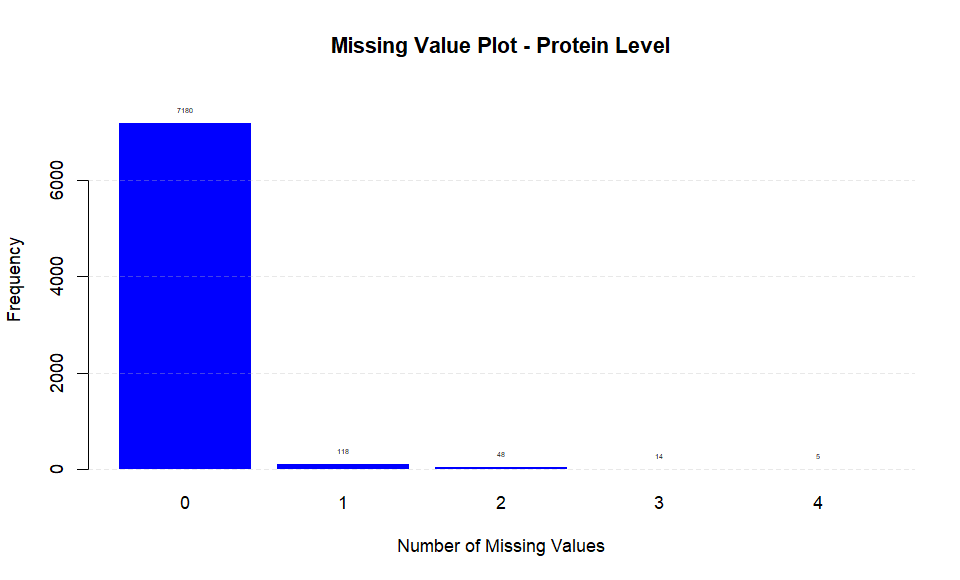

In [5]:
fig <- missing_value_plot(filtered, meta, data_scale = "log2")

In [6]:
missing_features <- missing_protein_table(filtered, meta, id=FALSE)
print(head(missing_features, 10))

n_MissingProteinValues,Counts,%_missing_values
0,7180,97.48812
1,118,1.60217
2,48,0.65173
3,14,0.19009
4,5,0.06789


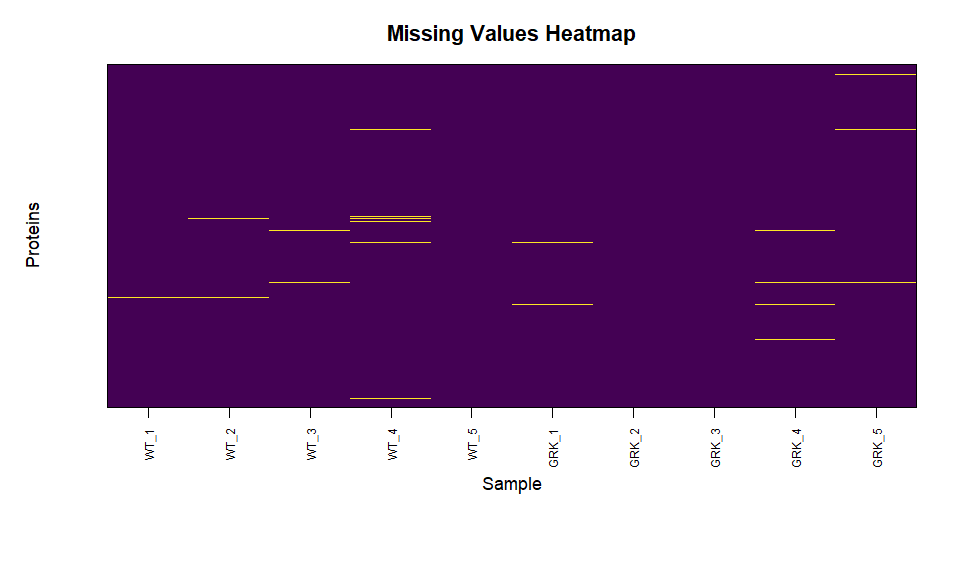

In [7]:
fig <- missing_value_heatmap(filtered, meta, id = FALSE, data_scale = "log2")

In [8]:
print(missing_sample_table(filtered, meta, id = FALSE, data_scale = "log2"))

Sample,Counts,%_missing_values
WT_1,22,0.29871
WT_2,35,0.47522
WT_3,29,0.39375
WT_4,32,0.43449
WT_5,19,0.25798
GRK_1,24,0.32587
GRK_2,23,0.31229
GRK_3,23,0.31229
GRK_4,33,0.44807
GRK_5,36,0.48880


## Imputation

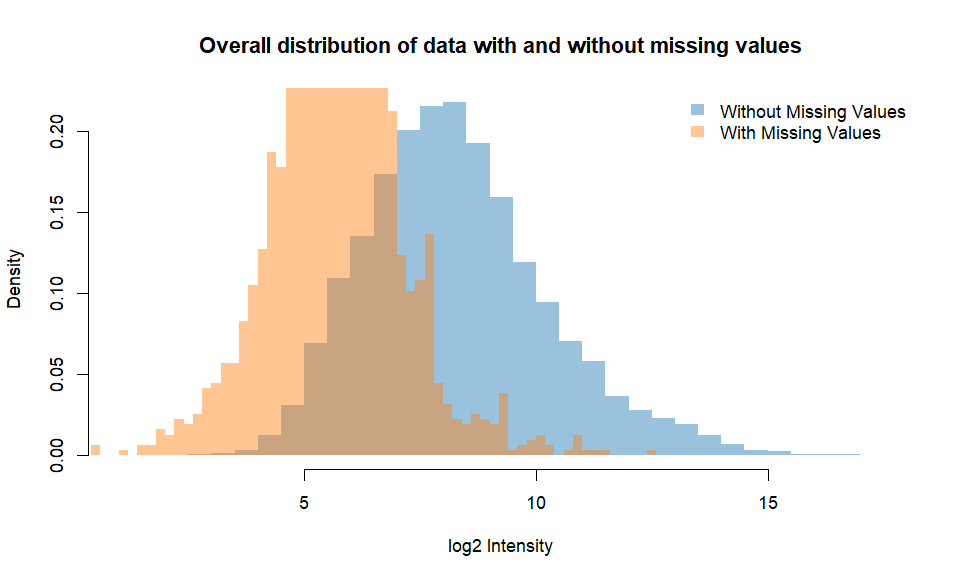

In [9]:
imputed <- impute_values(filtered, meta, seed = 1)
fig <- impute_values(filtered, meta, ret = 1, seed = 1)

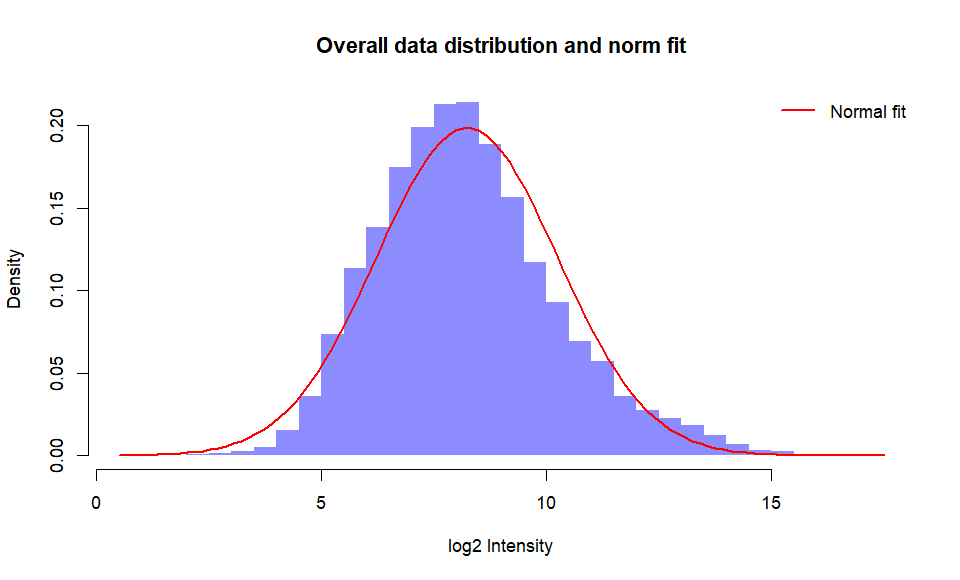

In [10]:
fig <- impute_values(filtered, meta, ret = 2, seed = 1)

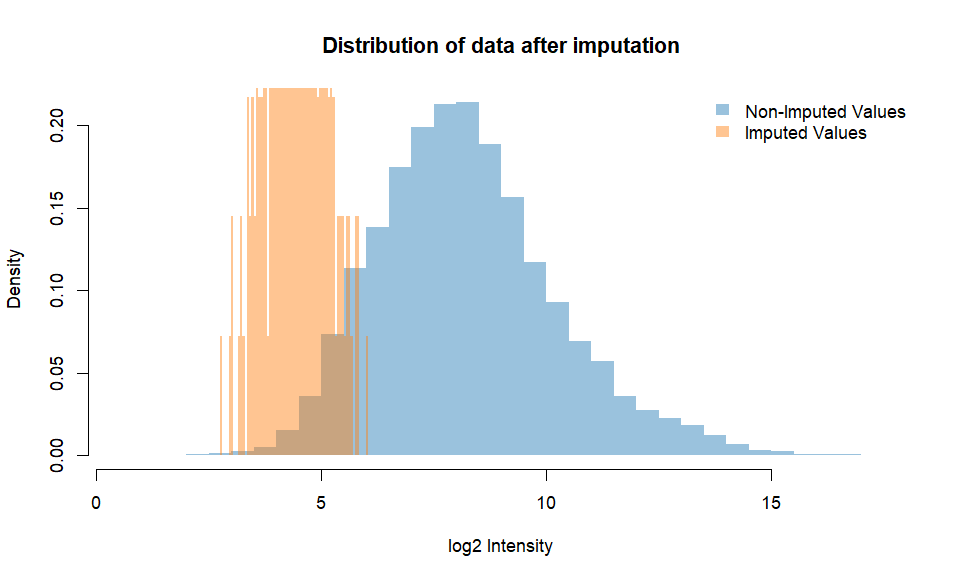

In [11]:
fig <- impute_values(filtered, meta, ret = 3, seed = 1)

In [12]:
print(head(imputed, 10))

PG.ProteinAccessions,GeneNames,PG.ProteinDescriptions,ProteinNames,PG.IsCandidate,PG.Completeness,PG.CV,PG.AvgLog2Quantity,[1] 20240822_nElute_tims1_JM_HEK293_WP_GRK_1_Slot1-73_1_8070.d.PG.Log2Quantity,[2] 20240822_nElute_tims1_JM_HEK293_WP_GRK_2_Slot1-74_1_8071.d.PG.Log2Quantity,[3] 20240822_nElute_tims1_JM_HEK293_WP_GRK_3_Slot1-75_1_8072.d.PG.Log2Quantity,[4] 20240822_nElute_tims1_JM_HEK293_WP_GRK_4_Slot1-76_1_8073.d.PG.Log2Quantity,[5] 20240822_nElute_tims1_JM_HEK293_WP_GRK_5_Slot1-77_1_8074.d.PG.Log2Quantity,[6] 20240822_nElute_tims1_JM_HEK293_WP_WT_1_Slot1-61_1_8064.d.PG.Log2Quantity,[7] 20240822_nElute_tims1_JM_HEK293_WP_WT_2_Slot1-62_1_8065.d.PG.Log2Quantity,[8] 20240822_nElute_tims1_JM_HEK293_WP_WT_3_Slot1-63_1_8066.d.PG.Log2Quantity,[9] 20240822_nElute_tims1_JM_HEK293_WP_WT_4_Slot1-64_1_8067.d.PG.Log2Quantity,[10] 20240822_nElute_tims1_JM_HEK293_WP_WT_5_Slot1-65_1_8068.d.PG.Log2Quantity
A0A024R1R8;Q9Y2S6,TMA7B;TMA7,Translation machinery-associated protein 7B;Translation machinery-associated protein 7,TMA7B_HUMAN;TMA7_HUMAN,False,100,0.14578,10.95571,10.99060,10.83470,10.56175,11.06052,11.07736,10.99423,10.84438,11.10142,10.76616,11.32602
A0A024RBG1,NUDT4B,Diphosphoinositol polyphosphate phosphohydrolase NUDT4B,NUD4B_HUMAN,False,100,0.12792,7.20808,7.32860,7.18115,7.14206,7.30470,7.13028,7.59448,6.98336,7.13267,7.02970,7.25382
A0A096LP01,SMIM26,Small integral membrane protein 26,SIM26_HUMAN,True,90,0.46391,4.34109,4.07368,4.99797,4.09650,4.08910,5.43577,4.07035,4.79825,3.91311,3.91409,3.75465
A0A0B4J2A2,PPIAL4C,Peptidyl-prolyl cis-trans isomerase A-like 4C,PAL4C_HUMAN,False,100,0.06373,14.95530,14.87092,14.90439,14.83806,14.93559,14.91644,14.89902,15.01867,15.07217,14.97879,15.11897
A0A0B4J2D5;P0DPI2,GATD3B;GATD3,"Putative glutamine amidotransferase-like class 1 domain-containing protein 3B, mitochondrial;Glutamine amidotransferase-like class 1 domain-containing protein 3, mitochondrial",GAL3B_HUMAN;GAL3A_HUMAN,False,100,0.05906,10.92248,10.77845,10.90908,10.87242,10.87605,10.83588,10.98532,10.93139,11.06345,10.97352,10.99927
A0A0B4J2F0,PIGBOS1,Protein PIGBOS1,PIOS1_HUMAN,False,90,0.08902,6.84877,6.91853,4.30541,6.83512,6.98554,6.72804,6.93817,6.68795,7.03881,6.70464,6.80216
A0A0U1RRE5,NBDY,Negative regulator of P-body association,NBDY_HUMAN,False,100,0.19920,7.33794,7.60634,7.67545,7.23554,7.03491,7.48533,7.49203,7.27441,6.59041,7.57957,7.40543
A0A1W2PPL8,TAF11L14,TATA-box-binding protein-associated factor 11-like protein 14,TFKLN_HUMAN,False,100,0.06284,8.87661,9.00776,8.99492,8.85487,8.79393,8.76525,8.84058,8.92434,8.95117,8.76103,8.87230
A0A2Z4LIS9,FOXO3B,Forkhead box protein O3B,FXO3B_HUMAN,False,90,0.12235,6.58604,6.52882,6.52472,6.42873,4.81580,6.61996,6.74963,6.89629,6.62510,6.61030,6.29085
A0A499FJF3;Q6P4F7,;ARHGAP11A,Rho-GAP domain-containing protein;Rho GTPase-activating protein 11A,A0A499FJF3_HUMAN;RHGBA_HUMAN,False,100,0.26073,6.00335,6.11196,5.80025,5.81956,5.96550,5.37045,6.01199,6.54559,6.55530,6.20316,5.64974


## QC

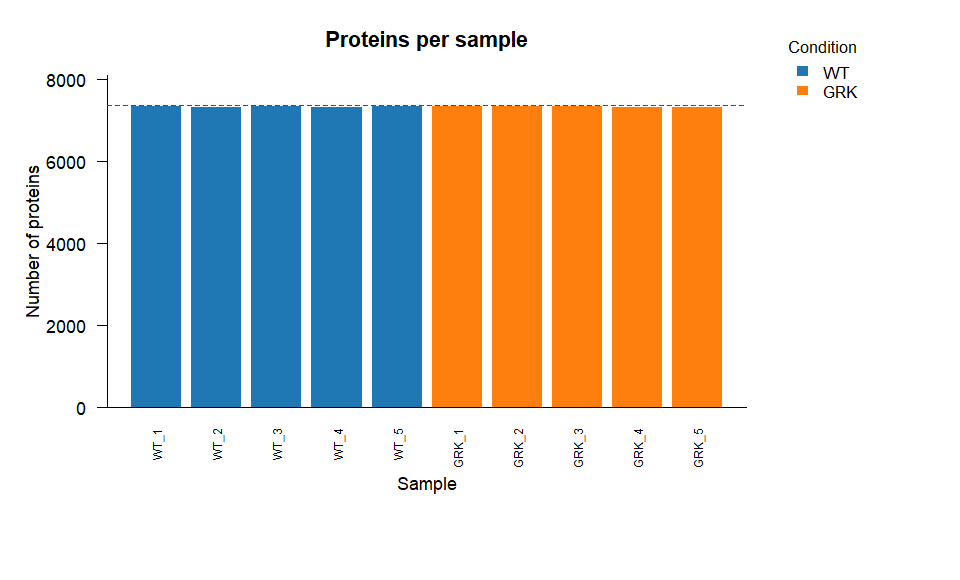

In [13]:
linear <- inverse_log2_transform_data(filtered, meta)
fig <- coverage_plot(filtered, meta, id = FALSE, data_scale = "log2")

In [14]:
coverage <- qc_coverage_table(filtered, meta)
print(coverage)

Sample,Number
WT_1,7343
WT_2,7330
WT_3,7336
WT_4,7333
WT_5,7346
GRK_1,7341
GRK_2,7342
GRK_3,7342
GRK_4,7332
GRK_5,7329


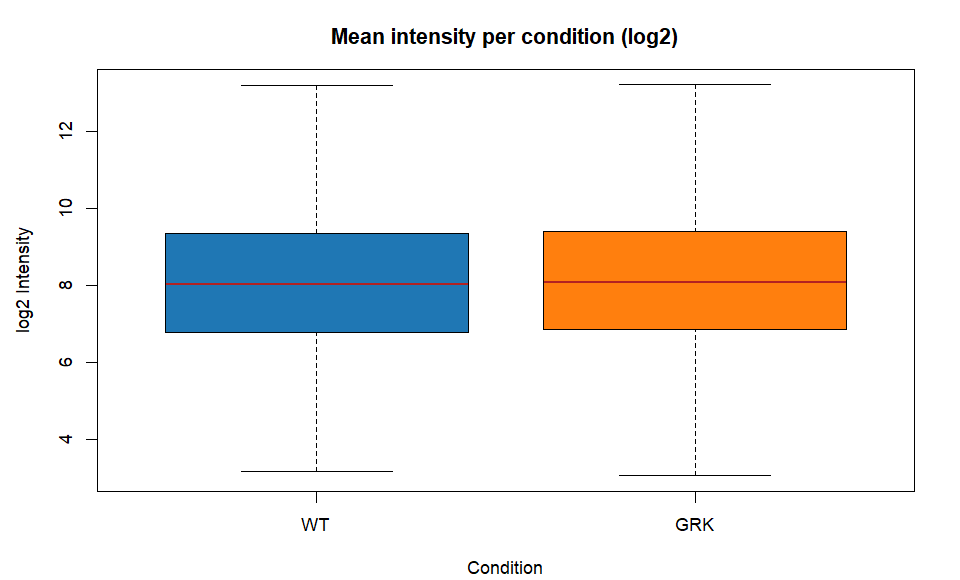

In [15]:
fig <- boxplot_int(filtered, meta, data_scale = "log2")

In [16]:
intensity_summary <- qc_boxplot_table(filtered, meta)
print(head(intensity_summary, 10))

Condition,mean,median,Q1,Q3,lower_whisker,upper_whisker
WT,8.21,8.03,6.79,9.35,3.17,13.19
GRK,8.24,8.07,6.85,9.40,3.07,13.21


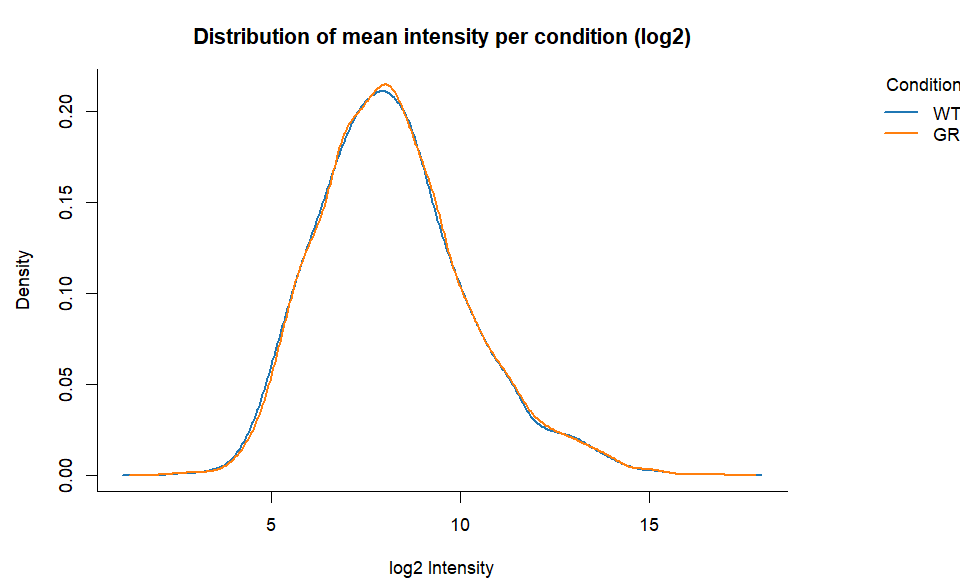

In [17]:
fig <- histo_int(filtered, meta, data_scale = "log2")

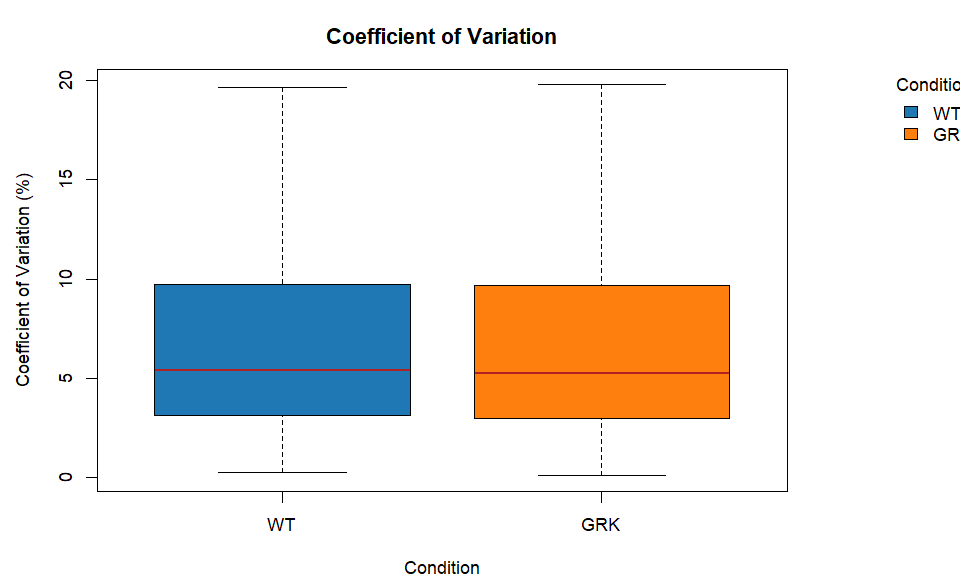

In [18]:
fig <- cov_plot(linear, meta, data_scale = "linear")

In [19]:
cv_summary <- qc_cv_table(linear, meta)
print(head(cv_summary, 10))

Condition,mean,median,Q1,Q3,lower_whisker,upper_whisker
WT,7.64,5.43,3.15,9.74,0.27,19.63
GRK,7.62,5.25,2.97,9.70,0.11,19.78


In [20]:
feature_cvs <- qc_feature_cvs(linear, meta)
print(head(feature_cvs, 10))

PG.ProteinAccessions,GeneNames,PG.ProteinDescriptions,ProteinNames,PG.IsCandidate,PG.Completeness,PG.CV,PG.AvgLog2Quantity,WT CV (%),GRK CV (%)
A0A024R1R8;Q9Y2S6,TMA7B;TMA7,Translation machinery-associated protein 7B;Translation machinery-associated protein 7,TMA7B_HUMAN;TMA7_HUMAN,False,100,0.14578,10.95571,15.70476,13.98130
A0A024RBG1,NUDT4B,Diphosphoinositol polyphosphate phosphohydrolase NUDT4B,NUD4B_HUMAN,False,100,0.12792,7.20808,18.07448,6.49633
A0A096LP01,SMIM26,Small integral membrane protein 26,SIM26_HUMAN,True,90,0.46391,4.34109,32.88443,46.58793
A0A0B4J2A2,PPIAL4C,Peptidyl-prolyl cis-trans isomerase A-like 4C,PAL4C_HUMAN,False,100,0.06373,14.95530,5.84617,2.67089
A0A0B4J2D5;P0DPI2,GATD3B;GATD3,"Putative glutamine amidotransferase-like class 1 domain-containing protein 3B, mitochondrial;Glutamine amidotransferase-like class 1 domain-containing protein 3, mitochondrial",GAL3B_HUMAN;GAL3A_HUMAN,False,100,0.05906,10.92248,3.34747,3.41550
A0A0B4J2F0,PIGBOS1,Protein PIGBOS1,PIOS1_HUMAN,False,90,0.08902,6.84877,10.65759,7.63218
A0A0U1RRE5,NBDY,Negative regulator of P-body association,NBDY_HUMAN,False,100,0.19920,7.33794,23.48186,17.79415
A0A1W2PPL8,TAF11L14,TATA-box-binding protein-associated factor 11-like protein 14,TFKLN_HUMAN,False,100,0.06284,8.87661,5.12357,7.84185
A0A2Z4LIS9,FOXO3B,Forkhead box protein O3B,FXO3B_HUMAN,False,90,0.12235,6.58604,14.96664,5.40616
A0A499FJF3;Q6P4F7,;ARHGAP11A,Rho-GAP domain-containing protein;Rho GTPase-activating protein 11A,A0A499FJF3_HUMAN;RHGBA_HUMAN,False,100,0.26073,6.00335,25.13253,18.05552


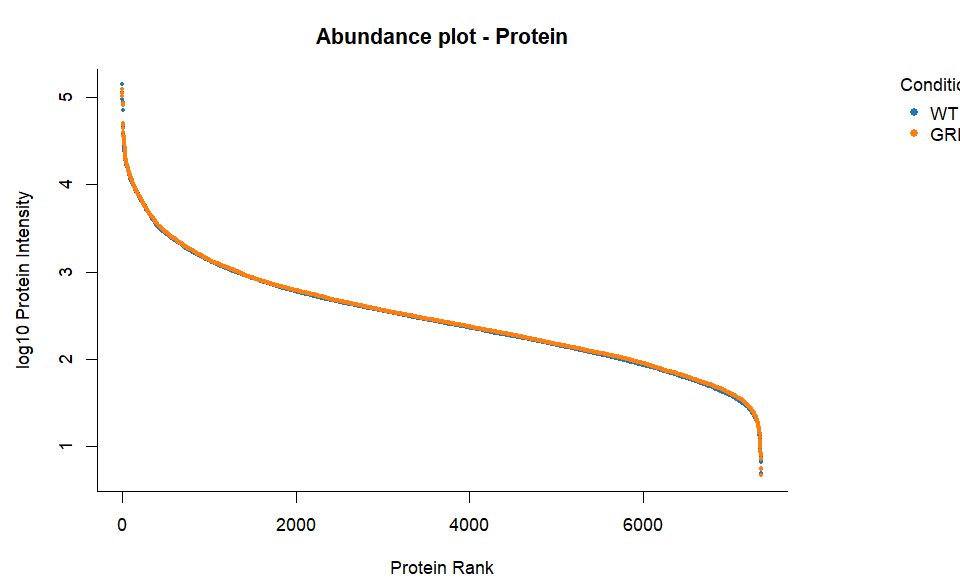

In [21]:
fig <- abundance_plot(linear, meta, workflow = "Protein", data_scale = "linear")

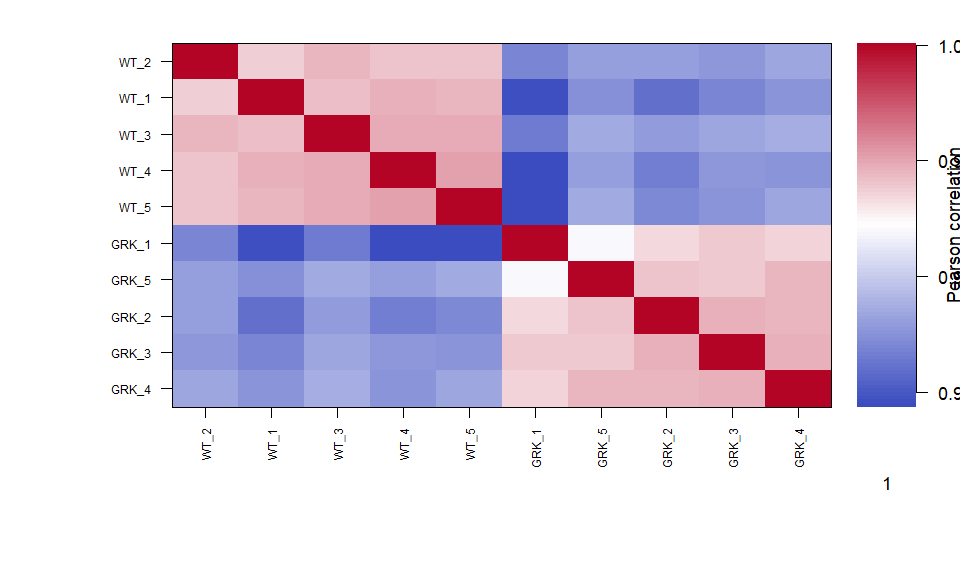

In [22]:
fig <- corr_plot(filtered, meta, id = FALSE, data_scale = "log2")

In [23]:
correlations <- sample_correlation_matrix(filtered, meta, id=FALSE)
print(head(correlations, 10))

,WT_1,WT_2,WT_3,WT_4,WT_5,GRK_1,GRK_2,GRK_3,GRK_4,GRK_5
WT_1,1.00000,0.99366,0.99421,0.99458,0.99449,0.98470,0.98609,0.98702,0.98768,0.98751
WT_2,0.99366,1.00000,0.99444,0.99408,0.99397,0.98701,0.98806,0.98784,0.98840,0.98816
WT_3,0.99421,0.99444,1.00000,0.99473,0.99483,0.98648,0.98792,0.98848,0.98870,0.98855
WT_4,0.99458,0.99408,0.99473,1.00000,0.99517,0.98446,0.98676,0.98778,0.98761,0.98808
WT_5,0.99449,0.99397,0.99483,0.99517,1.00000,0.98445,0.98710,0.98761,0.98842,0.98851
GRK_1,0.98470,0.98701,0.98648,0.98446,0.98445,1.00000,0.99342,0.99386,0.99351,0.99204
GRK_2,0.98609,0.98806,0.98792,0.98676,0.98710,0.99342,1.00000,0.99457,0.99445,0.99403
GRK_3,0.98702,0.98784,0.98848,0.98778,0.98761,0.99386,0.99457,1.00000,0.99466,0.99393
GRK_4,0.98768,0.98840,0.98870,0.98761,0.98842,0.99351,0.99445,0.99466,1.00000,0.99449
GRK_5,0.98751,0.98816,0.98855,0.98808,0.98851,0.99204,0.99403,0.99393,0.99449,1.00000


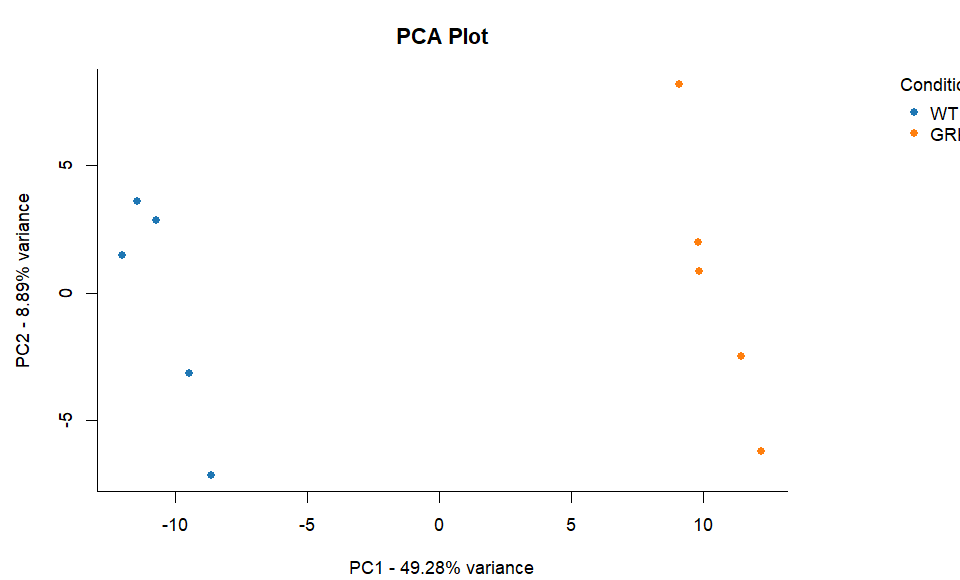

In [24]:
fig <- pca_plot(filtered, meta)

In [25]:
scores <- pca_scores(filtered, meta)
print(head(scores, 10))

PC1,PC2,sample,condition
-12.01731,1.49028,[6] 20240822_nElute_tims1_JM_HEK293_WP_WT_1_Slot1-61_1_8064.d.PG.Log2Quantity,WT
-8.63929,-7.14943,[7] 20240822_nElute_tims1_JM_HEK293_WP_WT_2_Slot1-62_1_8065.d.PG.Log2Quantity,WT
-9.49569,-3.13736,[8] 20240822_nElute_tims1_JM_HEK293_WP_WT_3_Slot1-63_1_8066.d.PG.Log2Quantity,WT
-11.45992,3.60475,[9] 20240822_nElute_tims1_JM_HEK293_WP_WT_4_Slot1-64_1_8067.d.PG.Log2Quantity,WT
-10.73227,2.85120,[10] 20240822_nElute_tims1_JM_HEK293_WP_WT_5_Slot1-65_1_8068.d.PG.Log2Quantity,WT
12.18888,-6.20617,[1] 20240822_nElute_tims1_JM_HEK293_WP_GRK_1_Slot1-73_1_8070.d.PG.Log2Quantity,GRK
11.43001,-2.46315,[2] 20240822_nElute_tims1_JM_HEK293_WP_GRK_2_Slot1-74_1_8071.d.PG.Log2Quantity,GRK
9.79146,1.99664,[3] 20240822_nElute_tims1_JM_HEK293_WP_GRK_3_Slot1-75_1_8072.d.PG.Log2Quantity,GRK
9.85228,0.84982,[4] 20240822_nElute_tims1_JM_HEK293_WP_GRK_4_Slot1-76_1_8073.d.PG.Log2Quantity,GRK
9.08184,8.16344,[5] 20240822_nElute_tims1_JM_HEK293_WP_GRK_5_Slot1-77_1_8074.d.PG.Log2Quantity,GRK


## Differential abundance

In [26]:
volcano <- volcano_data_f(filtered, meta, conditions[1], conditions[2], workflow = "Protein", test_type = "unpaired")
print(table(volcano$significance))


  Downregulated Not significant     Upregulated 
             51            7306               8 


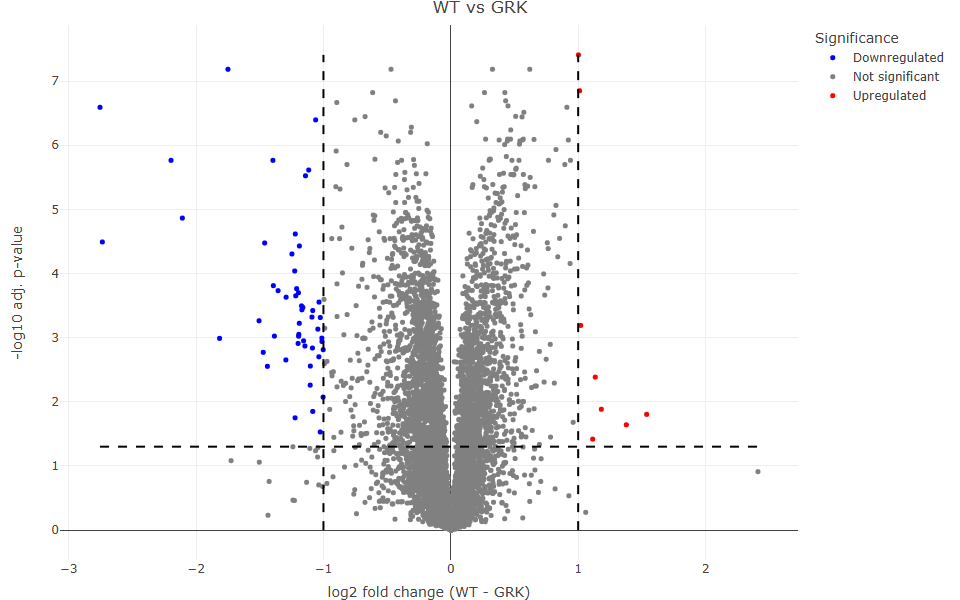

In [27]:
fig <- volcano_plot(volcano, conditions[1], conditions[2])
fig

In [28]:
print(head(volcano, 10))

ProteinNames,log2FC,pval,adj_pval,selected_pval,se,dof,zero_variance,significance,neg_log10_selected_pval
TMA7B_HUMAN;TMA7_HUMAN,0.10146,0.48233,0.59744,0.59744,0.13771,8,FALSE,Not significant,0.22371
NUD4B_HUMAN,-0.01855,0.87790,0.91557,0.91557,0.11695,8,FALSE,Not significant,0.03831
SIM26_HUMAN,-0.56475,0.16250,0.26101,0.26101,0.36179,7,FALSE,Not significant,0.58334
PAL4C_HUMAN,0.12444,0.01754,0.04558,0.04558,0.04173,8,FALSE,Not significant,1.34126
GAL3B_HUMAN;GAL3A_HUMAN,0.13621,0.00226,0.00913,0.00913,0.03090,8,FALSE,Not significant,2.03971
PIOS1_HUMAN,-0.03246,0.73190,0.81028,0.81028,0.09103,7,FALSE,Not significant,0.09136
NBDY_HUMAN,-0.13914,0.53274,0.64236,0.64236,0.21344,8,FALSE,Not significant,0.19222
TFKLN_HUMAN,-0.01346,0.82919,0.87896,0.87896,0.06040,8,FALSE,Not significant,0.05603
FXO3B_HUMAN,0.10887,0.38922,0.50998,0.50998,0.11861,7,FALSE,Not significant,0.29245
A0A499FJF3_HUMAN;RHGBA_HUMAN,0.37961,0.11001,0.19268,0.19268,0.21122,8,FALSE,Not significant,0.71517


In [29]:
protein_untested <- volcano_untested_table(filtered, meta, conditions[1], conditions[2], kind="protein")
print(head(protein_untested, 10))

ProteinNames,GeneNames,n_WT,mean_WT,n_GRK,mean_GRK,reason


In [30]:
welch <- volcano_data_f(filtered, meta, conditions[1], conditions[2], workflow = "Protein", test_type = "unpaired_welch")
print(table(welch$significance))


  Downregulated Not significant     Upregulated 
             50            7308               7 


In [31]:
volcano_imputed <- volcano_data_f(imputed, meta, conditions[1], conditions[2], workflow = "Protein", observed = filtered)
print(head(volcano_imputed[c("ProteinNames", "log2FC", "adj_pval", "imputed_values")], 5))

ProteinNames,log2FC,adj_pval,imputed_values
TMA7B_HUMAN;TMA7_HUMAN,0.10146,0.59703,0
NUD4B_HUMAN,-0.01855,0.91583,0
SIM26_HUMAN,-0.44852,0.33397,1
PAL4C_HUMAN,0.12444,0.04567,0
GAL3B_HUMAN;GAL3A_HUMAN,0.13621,0.00913,0


## ANOVA

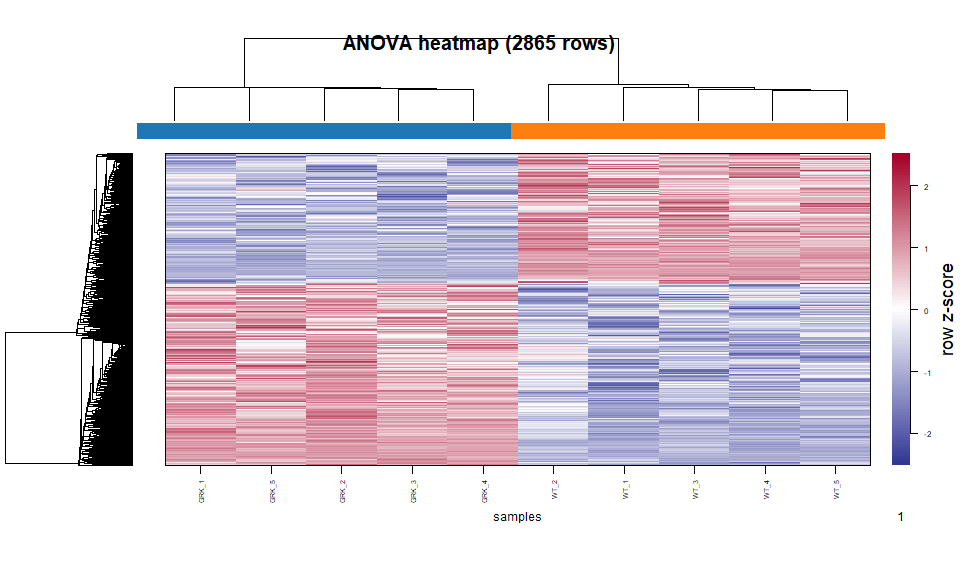

In [32]:
anova <- anova_data_f(filtered, meta)
fig <- withCallingHandlers(anova_plot(anova, meta), warning = function(w) {
  if (grepl("features dropped for clustering", conditionMessage(w), fixed = TRUE)) invokeRestart("muffleWarning")
})

In [33]:
print(head(anova, 10))

,ProteinNames,[6] 20240822_nElute_tims1_JM_HEK293_WP_WT_1_Slot1-61_1_8064.d.PG.Log2Quantity,[7] 20240822_nElute_tims1_JM_HEK293_WP_WT_2_Slot1-62_1_8065.d.PG.Log2Quantity,[8] 20240822_nElute_tims1_JM_HEK293_WP_WT_3_Slot1-63_1_8066.d.PG.Log2Quantity,[9] 20240822_nElute_tims1_JM_HEK293_WP_WT_4_Slot1-64_1_8067.d.PG.Log2Quantity,[10] 20240822_nElute_tims1_JM_HEK293_WP_WT_5_Slot1-65_1_8068.d.PG.Log2Quantity,[1] 20240822_nElute_tims1_JM_HEK293_WP_GRK_1_Slot1-73_1_8070.d.PG.Log2Quantity,[2] 20240822_nElute_tims1_JM_HEK293_WP_GRK_2_Slot1-74_1_8071.d.PG.Log2Quantity,[3] 20240822_nElute_tims1_JM_HEK293_WP_GRK_3_Slot1-75_1_8072.d.PG.Log2Quantity,[4] 20240822_nElute_tims1_JM_HEK293_WP_GRK_4_Slot1-76_1_8073.d.PG.Log2Quantity,[5] 20240822_nElute_tims1_JM_HEK293_WP_GRK_5_Slot1-77_1_8074.d.PG.Log2Quantity,f_statistic,pval,adj_pval,selected_pval,significance,neg_log10_selected_pval,zero_variance,mean_WT,mean_GRK
1081,NFM_HUMAN,13.19908,13.23687,13.19760,13.19285,13.19278,12.22078,12.23510,12.17769,12.16123,12.21538,3804.494,0,0,0,Significant,7.40808,FALSE,13.20384,12.20204
4757,PO210_HUMAN,8.51596,8.55388,8.52621,8.53405,8.52763,8.99129,8.99400,9.02569,8.99484,8.99817,2769.323,0,0,0,Significant,7.18379,FALSE,8.53154,9.00080
2649,AKA12_HUMAN,9.83570,9.87464,9.82879,9.81323,9.81098,9.22451,9.21999,9.19469,9.21691,9.20736,2404.204,0,0,0,Significant,7.18379,FALSE,9.83267,9.21269
1737,MCM7_HUMAN,11.90918,11.91434,11.91949,11.92350,11.89341,11.59598,11.58650,11.58263,11.58934,11.57032,2350.683,0,0,0,Significant,7.18379,FALSE,11.91198,11.58495
1262,ANXA3_HUMAN,7.55982,7.59357,7.61512,7.55695,7.44607,9.24131,9.27865,9.38002,9.31019,9.31022,2233.080,0,0,0,Significant,7.18379,FALSE,7.55431,9.30408
1080,NFL_HUMAN,12.51349,12.56669,12.54394,12.51395,12.49945,11.54608,11.57680,11.49201,11.45730,11.51018,1758.208,0,0,0,Significant,6.84914,FALSE,12.52751,11.51647
6362,INO1_HUMAN,9.91088,9.94820,9.91213,9.92797,9.92025,10.55366,10.48749,10.55451,10.52940,10.56192,1621.504,0,0,0,Significant,6.82043,FALSE,9.92389,10.53740
1654,PRDX6_HUMAN,13.93130,13.94998,13.94935,13.95225,13.92464,13.67605,13.66943,13.68943,13.67182,13.67787,1594.691,0,0,0,Significant,6.82043,FALSE,13.94150,13.67692
1091,ANXA2_HUMAN,13.35360,13.39192,13.39908,13.36330,13.36657,12.96704,12.95450,12.93524,12.93742,12.95937,1561.878,0,0,0,Significant,6.82043,FALSE,13.37489,12.95072
6469,SYIM_HUMAN,10.00766,10.01073,9.99506,9.99411,10.04754,9.58573,9.60068,9.58149,9.56789,9.56606,1379.294,0,0,0,Significant,6.69206,FALSE,10.01102,9.58037


## GO over-representation

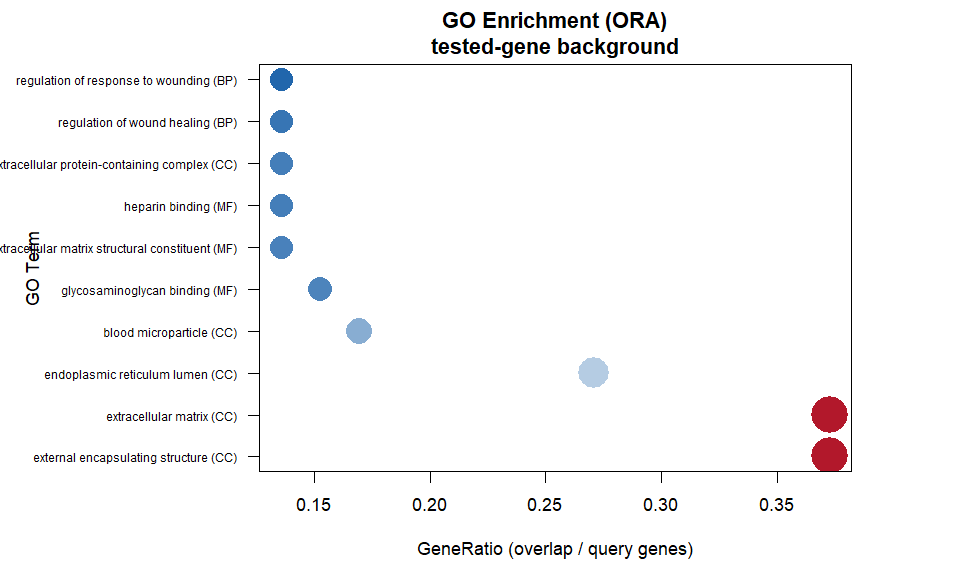

In [34]:
genes <- different_genes(filtered, meta, conditions[1], conditions[2], workflow = "Protein")
significant <- c(genes$Upregulated, genes$Downregulated)
ora <- enrichment_data(significant, background = genes$Background)
fig <- enrichment_analysis(significant, background = genes$Background)

In [35]:
print(head(ora, 10))

,source,term_id,term_name,term_size,intersection_size,query_size,gene_ratio,p_value,adj_p_value
433,CC,GO:0030312,external encapsulating structure,135,22,59,0.37288,0,0
456,CC,GO:0031012,extracellular matrix,135,22,59,0.37288,0,0
123,CC,GO:0005788,endoplasmic reticulum lumen,159,16,59,0.27119,0,0
913,CC,GO:0072562,blood microparticle,48,10,59,0.16949,0,0
112,MF,GO:0005539,glycosaminoglycan binding,52,9,59,0.15254,0,0
103,MF,GO:0005201,extracellular matrix structural constituent,38,8,59,0.13559,0,0
232,MF,GO:0008201,heparin binding,41,8,59,0.13559,0,0
987,CC,GO:0140392,extracellular protein-containing complex,41,8,59,0.13559,0,0
852,BP,GO:0061041,regulation of wound healing,47,8,59,0.13559,0,0
1029,BP,GO:1903034,regulation of response to wounding,59,8,59,0.13559,0,0


## Single protein and comparison

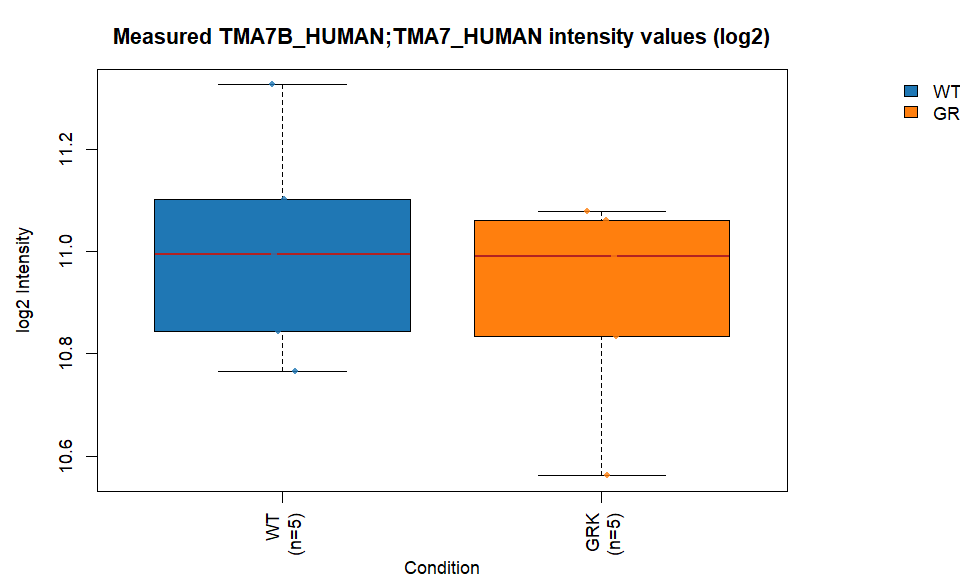

In [36]:
protein_id <- as.character(na.omit(filtered$ProteinNames)[1])
by_protein <- filtered
rownames(by_protein) <- by_protein$ProteinNames
fig <- boxplot_int_single_prot(by_protein, meta, protein_id, dots = TRUE)

In [37]:
protein_box <- single_protein_boxplot_table(filtered, meta, "protein", protein_id, unique(meta$condition))
print(head(protein_box, 10))

Condition,N,Mean,Median,Q1,Q3,Min,Max,SampleCount,SourceFeatureCount,SourceFeatures,Aggregation,Warning
WT,5,11.0064,10.9942,10.8444,11.1014,10.7662,11.3260,5,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
GRK,5,10.9050,10.9906,10.8347,11.0605,10.5617,11.0774,5,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,


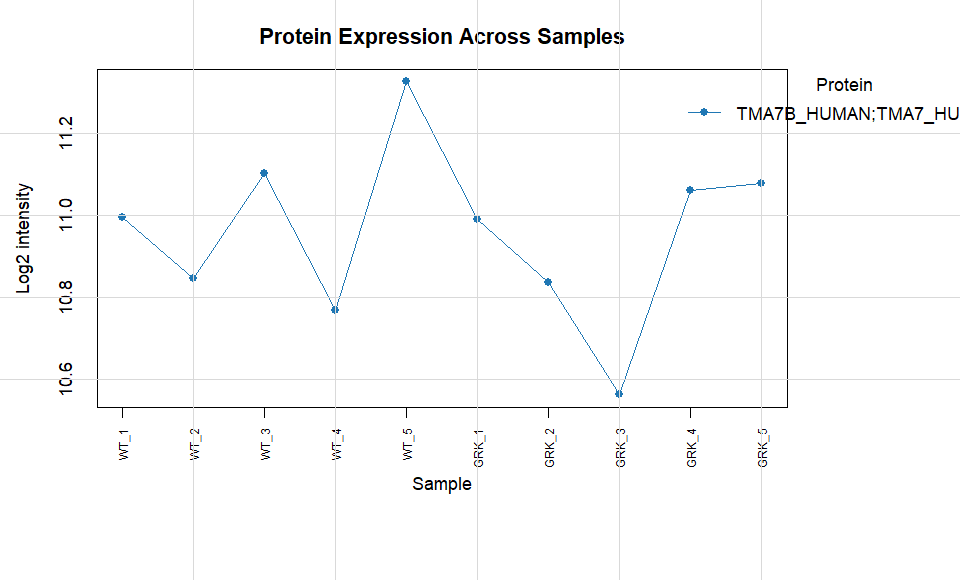

In [38]:
fig <- compare_prot_line(filtered, meta, conditions, c(protein_id), workflow = "Protein", id = FALSE)

In [39]:
protein_line <- single_protein_lineplot_table(filtered, meta, "protein", protein_id, conditions)
print(head(protein_line, 10))

Feature,Sample,Condition,Value,SampleCount,SourceFeatureCount,SourceFeatures,Aggregation,Warning
TMA7B_HUMAN;TMA7_HUMAN,WT_1,WT,10.9942,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
TMA7B_HUMAN;TMA7_HUMAN,WT_2,WT,10.8444,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
TMA7B_HUMAN;TMA7_HUMAN,WT_3,WT,11.1014,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
TMA7B_HUMAN;TMA7_HUMAN,WT_4,WT,10.7662,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
TMA7B_HUMAN;TMA7_HUMAN,WT_5,WT,11.3260,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
TMA7B_HUMAN;TMA7_HUMAN,GRK_1,GRK,10.9906,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
TMA7B_HUMAN;TMA7_HUMAN,GRK_2,GRK,10.8347,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
TMA7B_HUMAN;TMA7_HUMAN,GRK_3,GRK,10.5617,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
TMA7B_HUMAN;TMA7_HUMAN,GRK_4,GRK,11.0605,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,
TMA7B_HUMAN;TMA7_HUMAN,GRK_5,GRK,11.0774,10,1,TMA7B_HUMAN;TMA7_HUMAN,Per-sample median,


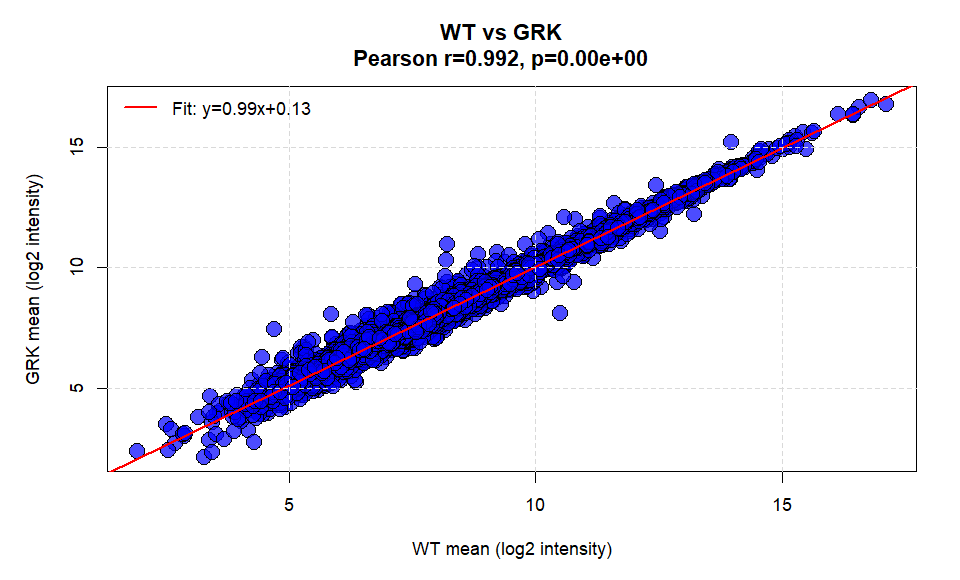

In [40]:
fig <- correlation_xy_intensity(filtered, meta, conditions[1], conditions[2])

In [41]:
pearson <- pearson_table(filtered, meta, "protein", mode="Condition", condition1=conditions[1], condition2=conditions[2])
print(head(pearson, 10))

Metric,Value
Left,WT
Right,GRK
Points,7365
PearsonR,0.991817


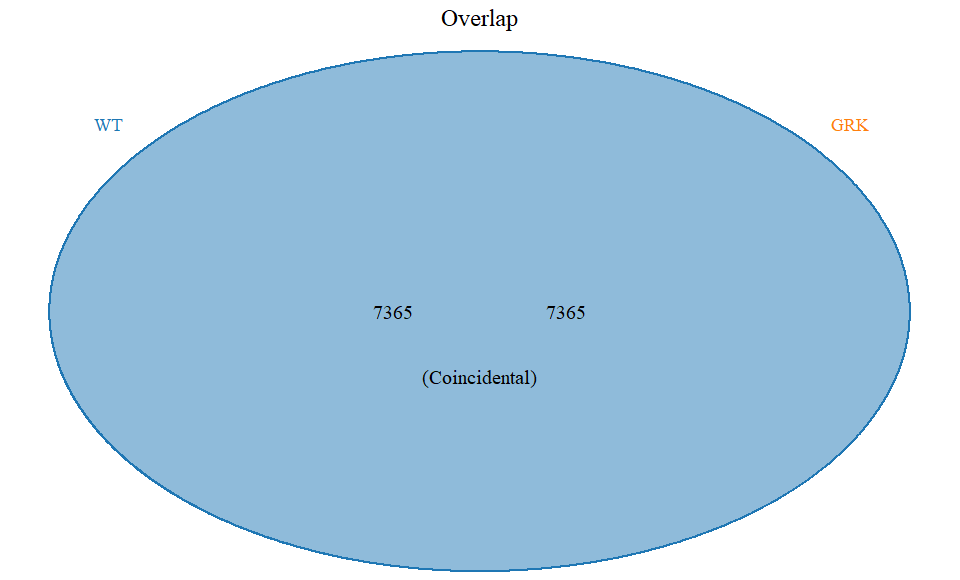

In [42]:
fig <- overlap_plot_condition(filtered, meta, conditions[1], conditions[2], data_scale = "log2")

In [43]:
overlap <- venn_table(filtered, meta, "protein", mode="Condition", first=conditions[1], second=conditions[2])
print(head(overlap, 10))

Region,Count
WT only,0
GRK only,0
WT & GRK,7365
Total WT,7365
Total GRK,7365


## Phosphosites

In [44]:
cat(nrow(sites), "phosphosite rows\n")

11916 phosphosite rows


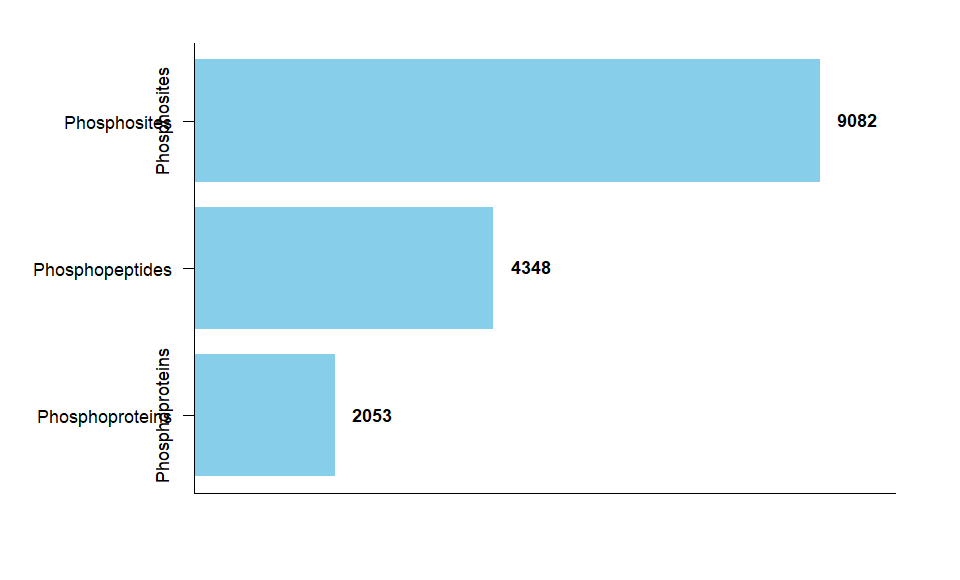

In [45]:
sites_filtered <- filter_data(sites, meta_sites, 3, mode = "per_group")
filter_phospho_contaminants <- TRUE
sites_filtered <- filter_contaminants(sites_filtered, enabled = filter_phospho_contaminants,
                                     categories = 1:5)
sites_filtered <- filter_localization(sites_filtered, 0)
fig <- simple_phos_site_plot(sites_filtered)

In [46]:
site_counts <- phospho_counts_table(sites_filtered)
print(head(site_counts, 10))

Term,Count
Phosphosites,9082
Phosphopeptides,4348
Phosphoproteins,2053


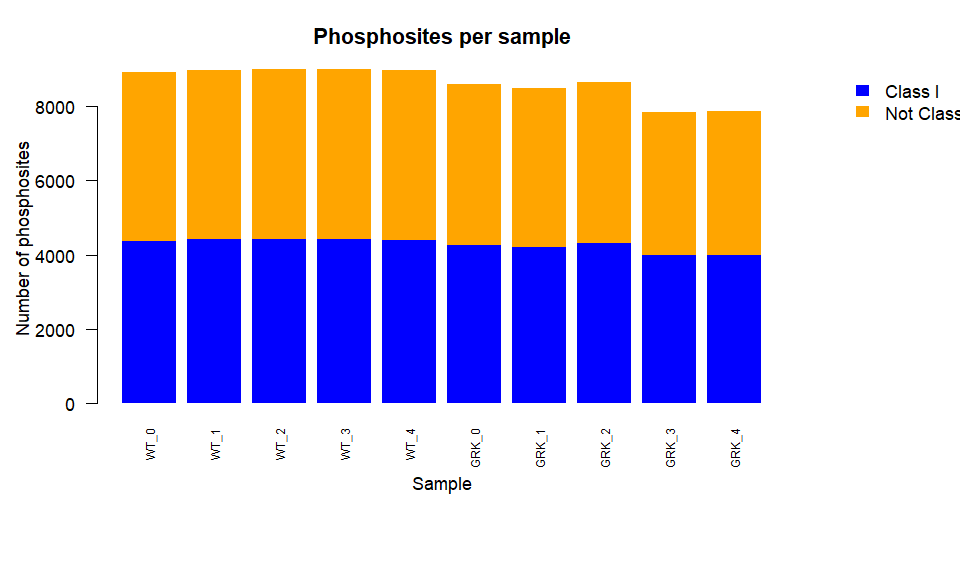

In [47]:
fig <- phossite_coverage_plot(sites_filtered, meta_sites, id = FALSE)

In [48]:
site_coverage <- phospho_coverage_table(sites_filtered, meta_sites, is_log2=TRUE)
print(head(site_coverage, 10))

Sample,Class I,Not Class I,Unclassified,Condition,Total
WT_1,4361,4544,0,WT,8905
WT_2,4410,4553,0,WT,8963
WT_3,4425,4578,0,WT,9003
WT_4,4420,4582,0,WT,9002
WT_5,4406,4566,0,WT,8972
GRK_1,4270,4326,0,GRK,8596
GRK_2,4215,4273,0,GRK,8488
GRK_3,4302,4344,0,GRK,8646
GRK_4,3994,3836,0,GRK,7830
GRK_5,3995,3857,0,GRK,7852


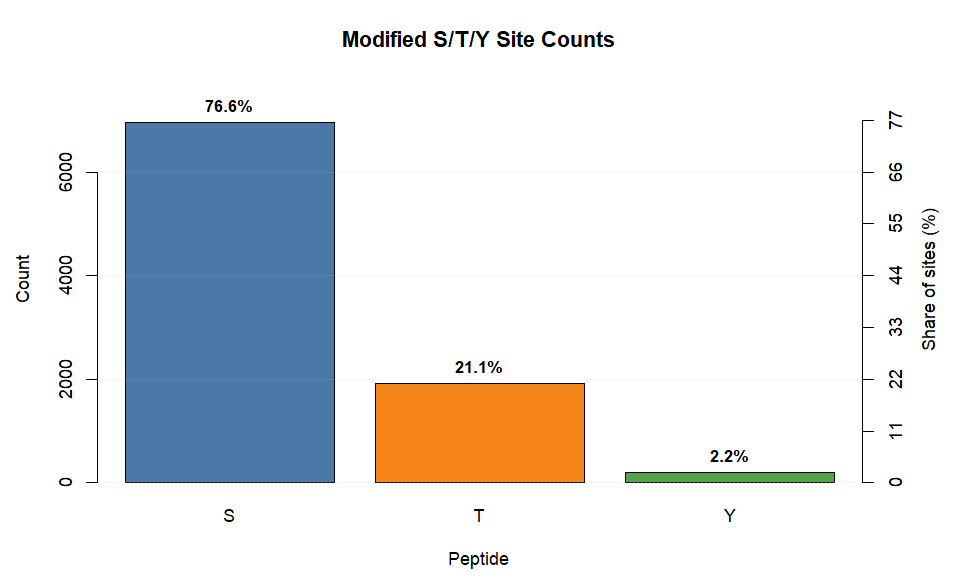

In [49]:
fig <- sty_plot(sites_filtered)

In [50]:
site_residues <- phospho_sty_table(sites_filtered)
print(head(site_residues, 10))

Residue,Count,Percentage
S,6958,76.61
T,1921,21.15
Y,203,2.24


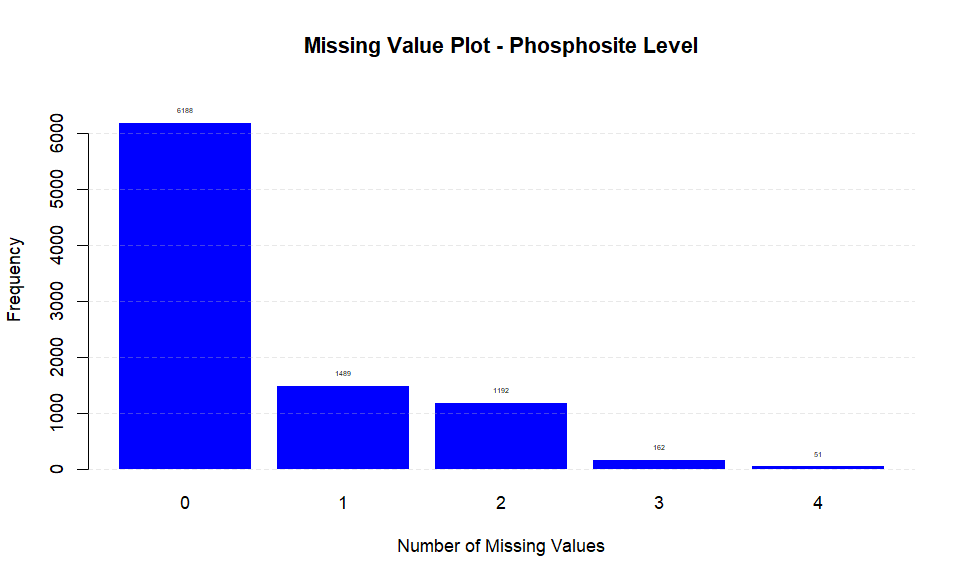

In [51]:
fig <- missing_value_plot(sites_filtered, meta_sites, data_scale = "log2")

In [52]:
missing_sites <- missing_protein_table(sites_filtered, meta_sites, id=FALSE)
print(head(missing_sites, 10))

n_MissingProteinValues,Counts,%_missing_values
0,6188,68.13477
1,1489,16.39507
2,1192,13.12486
3,162,1.78375
4,51,0.56155


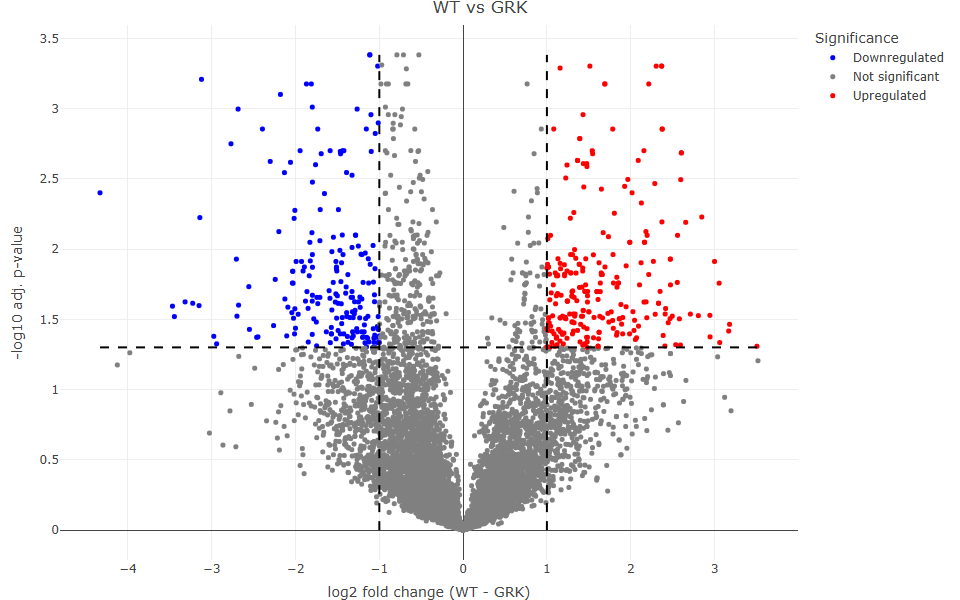

In [53]:
site_volcano <- volcano_data_f(sites_filtered, meta_sites, conditions[1], conditions[2], workflow = "Phosphosite")
fig <- volcano_plot(site_volcano, conditions[1], conditions[2])
fig

In [54]:
print(head(site_volcano, 10))

,PTM_Collapse_key,Protein_group,log2FC,pval,adj_pval,selected_pval,se,dof,zero_variance,significance,neg_log10_selected_pval
1,A0A590UK10~ARHGEF18_S1035_M1,A0A590UK10,0.27787,0.45740,0.67711,0.67711,0.35332,7,FALSE,Not significant,0.16934
2,A0A590UK10~ARHGEF18_S1037_M1,A0A590UK10,0.36265,0.43966,0.66241,0.66241,0.44268,7,FALSE,Not significant,0.17887
3,A0JLT2~MED19_S226_M1,A0JLT2,-0.50239,0.03377,0.15745,0.15745,0.19643,8,FALSE,Not significant,0.80285
5,A0JNW5~BLTP3B_S418_M1,A0JNW5,-0.38522,0.60737,0.77966,0.77966,0.71626,7,FALSE,Not significant,0.10809
6,A0JNW5~BLTP3B_S951_M1,A0JNW5,0.47104,0.57606,0.76021,0.76021,0.79695,6,FALSE,Not significant,0.11907
8,A0JNW5~BLTP3B_S987_M1,A0JNW5,1.10760,0.04139,0.17597,0.17597,0.42816,6,FALSE,Not significant,0.75457
9,A0JNW5~BLTP3B_S989_M1,A0JNW5,0.42116,0.24427,0.47936,0.47936,0.33132,7,FALSE,Not significant,0.31934
10,A0JNW5~BLTP3B_T420_M1,A0JNW5,0.78301,0.01525,0.09940,0.09940,0.24535,7,FALSE,Not significant,1.00262
11,A0MZ66~SHTN1_S492_M1,A0MZ66,-0.19467,0.64210,0.80095,0.80095,0.40311,8,FALSE,Not significant,0.09639
12,A0MZ66~SHTN1_S493_M1,A0MZ66,-0.04564,0.90285,0.95452,0.95452,0.36224,8,FALSE,Not significant,0.02021


In [55]:
phospho_untested <- volcano_untested_table(sites_filtered, meta_sites, conditions[1], conditions[2], kind="phospho")
print(head(phospho_untested, 10))

PTM_Collapse_key,Gene_group,UPD_seq,Protein_group,n_WT,mean_WT,n_GRK,mean_GRK,reason


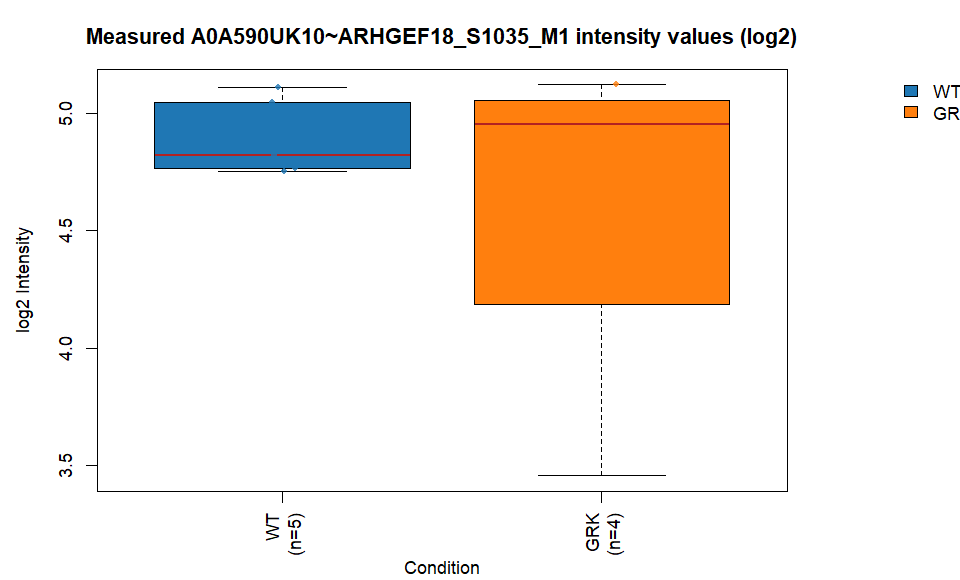

In [56]:
site_id <- as.character(na.omit(sites_filtered$PTM_Collapse_key)[1])
by_site <- sites_filtered
rownames(by_site) <- by_site$PTM_Collapse_key
fig <- boxplot_int_single_prot(by_site, meta_sites, site_id, dots = TRUE)

In [57]:
site_box <- single_protein_boxplot_table(sites_filtered, meta_sites, "phospho", site_id, unique(meta_sites$condition))
print(head(site_box, 10))

Condition,N,Mean,Median,Q1,Q3,Min,Max,SampleCount,SourceFeatureCount,SourceFeatures,Aggregation,Warning
WT,5,4.8996,4.8221,4.7643,5.0456,4.7540,5.1119,5,1,A0A590UK10~ARHGEF18_S1035_M1,Per-sample median,
GRK,4,4.6217,4.9536,4.5509,5.0244,3.4572,5.1224,4,1,A0A590UK10~ARHGEF18_S1035_M1,Per-sample median,


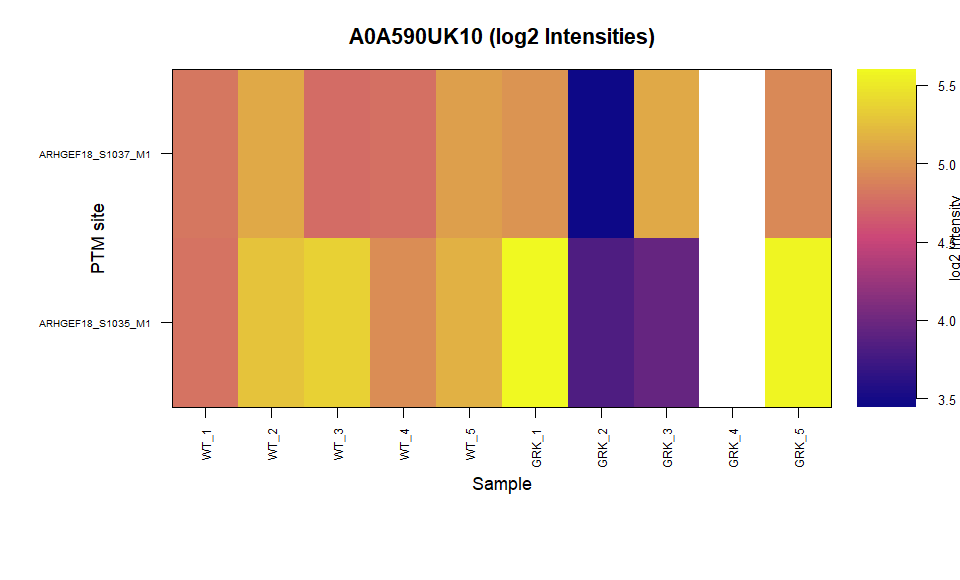

In [58]:
protein_of_site <- split_tokens(as.character(na.omit(sites_filtered$Protein_group)[1]))[1]
fig <- phossite_on_prot_regulation(sites_filtered, meta_sites, protein_of_site, conditions = conditions, id = FALSE)

In [59]:
site_heatmap <- single_protein_heatmap_table(sites_filtered, meta_sites, "phospho", protein_of_site, conditions, filter_m1=FALSE)
print(head(site_heatmap, 10))

Site,PTM_Collapse_key,WT_1,WT_2,WT_3,WT_4,WT_5,GRK_1,GRK_2,GRK_3,GRK_4,GRK_5
ARHGEF18_S1035_M1,A0A590UK10~ARHGEF18_S1035_M1,4.8221,5.1119,4.7540,4.7643,5.0456,4.9918,3.4572,5.1224,NA,4.9155
ARHGEF18_S1037_M1,A0A590UK10~ARHGEF18_S1037_M1,4.7836,5.2708,5.3409,4.9519,5.1544,5.5932,3.8295,3.9646,NA,5.5634


## Phosphoproteins

In [60]:
phosprot <- transform_phosprot(sites_filtered, meta_sites, mode = "robust_site_median",
                              data_scale = "log2", coverage_data = sites_filtered)
phosprot_filtered <- filter_data(phosprot, meta_sites, 3, mode = "per_group")
phosprot_filtered <- filter_contaminants(phosprot_filtered, enabled = filter_phospho_contaminants,
                                        categories = 1:5)
cat(nrow(sites_filtered), "retained sites;", nrow(phosprot_filtered), "phosphoproteins after filtering\n")

9082 retained sites; 2053 phosphoproteins after filtering


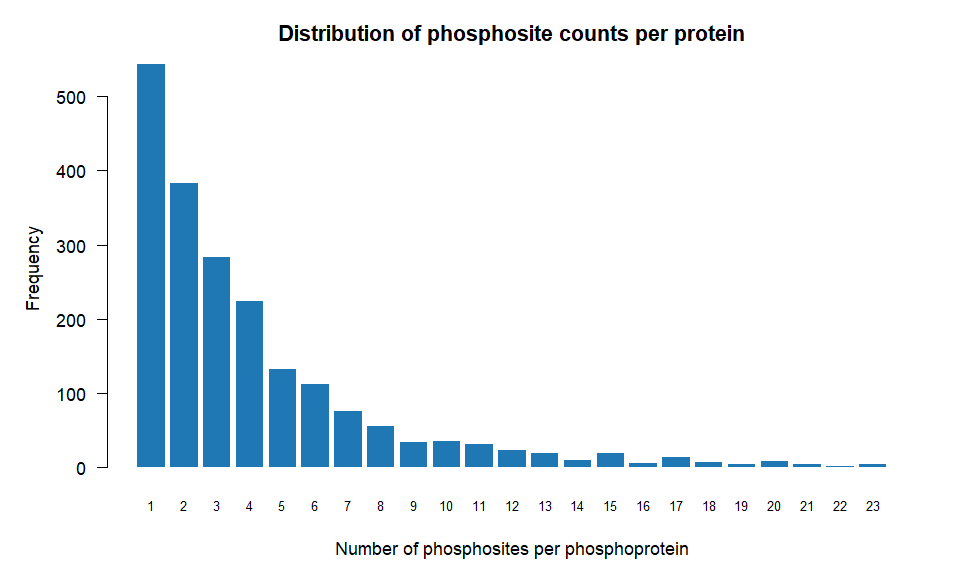

In [61]:
fig <- phossite_dist(phosprot_filtered, cutoff = 0.01)

In [62]:
site_distribution <- phospho_distribution_table(phosprot_filtered, cutoff=0.01)
print(site_distribution)

SiteCount,Frequency
1,543
2,383
3,284
4,224
5,132
6,113
7,76
8,56
9,34
10,36


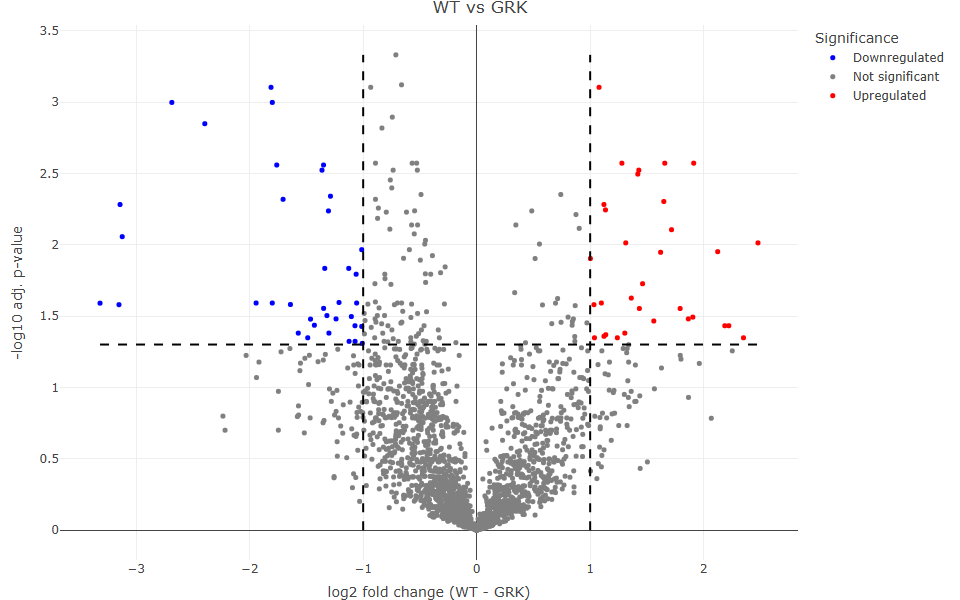

In [63]:
phosprot_volcano <- volcano_data_f(phosprot_filtered, meta_sites, conditions[1], conditions[2], workflow = "Phosphoprotein")
fig <- volcano_plot(phosprot_volcano, conditions[1], conditions[2])
fig

In [64]:
print(head(phosprot_volcano, 10))

,Phosphoprotein,site_num,PTM_Collapse_keys,log2FC,pval,adj_pval,selected_pval,se,dof,zero_variance,significance,neg_log10_selected_pval,n_measured__WT,n_fully_imputed__WT,n_partially_imputed__WT,n_imputed__WT,n_measured__GRK,n_fully_imputed__GRK,n_partially_imputed__GRK,n_imputed__GRK,imputed_values
20240822_nElute_tims1_JM_HEK293_PP_WT_1_Slot1-61_1_8077,A0A590UK10,2,A0A590UK10~ARHGEF18_S1035_M1;A0A590UK10~ARHGEF18_S1037_M1,0.32026,0.38869,0.60590,0.60590,0.34850,7,FALSE,Not significant,0.21760,5,0,0,0,4,0,0,0,0
20240822_nElute_tims1_JM_HEK293_PP_WT_1_Slot1-61_1_80771,A0JLT2,1,A0JLT2~MED19_S226_M1,-0.50239,0.03377,0.14752,0.14752,0.19643,8,FALSE,Not significant,0.83115,5,0,0,0,5,0,0,0,0
20240822_nElute_tims1_JM_HEK293_PP_WT_1_Slot1-61_1_80772,A0JNW5,5,A0JNW5~BLTP3B_S418_M1;A0JNW5~BLTP3B_S951_M1;A0JNW5~BLTP3B_S987_M1;A0JNW5~BLTP3B_S989_M1;A0JNW5~BLTP3B_T420_M1,0.44103,0.16161,0.36261,0.36261,0.28599,8,FALSE,Not significant,0.44056,5,0,0,0,5,0,0,0,0
20240822_nElute_tims1_JM_HEK293_PP_WT_1_Slot1-61_1_80773,A0MZ66,7,A0MZ66~SHTN1_S492_M1;A0MZ66~SHTN1_S493_M1;A0MZ66~SHTN1_S494_M1;A0MZ66~SHTN1_S506_M1;A0MZ66~SHTN1_T487_M1;A0MZ66~SHTN1_T496_M1;A0MZ66~SHTN1_T501_M1,-0.06102,0.84008,0.91836,0.91836,0.29270,8,FALSE,Not significant,0.03699,5,0,0,0,5,0,0,0,0
20240822_nElute_tims1_JM_HEK293_PP_WT_1_Slot1-61_1_80774,A1L170,1,A1L170~C1orf226_S18_M1,0.36036,0.42070,0.63367,0.63367,0.42133,7,FALSE,Not significant,0.19814,5,0,0,0,4,0,0,0,0
20240822_nElute_tims1_JM_HEK293_PP_WT_1_Slot1-61_1_80775,A1L390,1,A1L390~PLEKHG3_S76_M1,-0.77771,0.01060,0.07713,0.07713,0.23450,8,FALSE,Not significant,1.11275,5,0,0,0,5,0,0,0,0
20240822_nElute_tims1_JM_HEK293_PP_WT_1_Slot1-61_1_80776,A1X283,2,A1X283~SH3PXD2B_S291_M1;A1X283~SH3PXD2B_S293_M1,-0.37560,0.47482,0.68264,0.68264,0.49278,6,FALSE,Not significant,0.16581,5,0,0,0,3,0,0,0,0
20240822_nElute_tims1_JM_HEK293_PP_WT_1_Slot1-61_1_80777,A2RRP1,1,A2RRP1~NBAS_S2361_M1,-0.12003,0.84698,0.92100,0.92100,0.59942,7,FALSE,Not significant,0.03574,5,0,0,0,4,0,0,0,0
20240822_nElute_tims1_JM_HEK293_PP_WT_1_Slot1-61_1_80778,A3KMH1,1,A3KMH1~VWA8_S1346_M1,0.34813,0.32429,0.54348,0.54348,0.32839,7,FALSE,Not significant,0.26481,5,0,0,0,4,0,0,0,0
20240822_nElute_tims1_JM_HEK293_PP_WT_1_Slot1-61_1_80779,A4D1P6,1,A4D1P6~WDR91_S256_M1,-0.42687,0.37831,0.59515,0.59515,0.45772,8,FALSE,Not significant,0.22537,5,0,0,0,5,0,0,0,0


In [65]:
phosprot_untested <- volcano_untested_table(phosprot_filtered, meta_sites, conditions[1], conditions[2], kind="phosprot")
print(head(phosprot_untested, 10))

Phosphoprotein,Gene_group,UPD_seq,site_num,PTM_Collapse_keys,n_WT,mean_WT,n_GRK,mean_GRK,reason


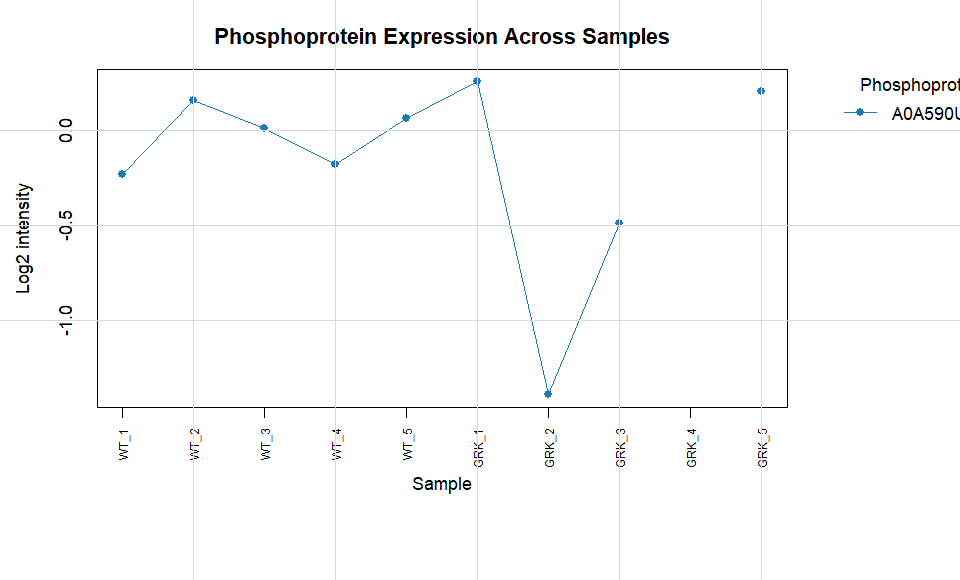

In [66]:
phosprot_id <- as.character(na.omit(phosprot_filtered$Phosphoprotein)[1])
fig <- compare_prot_line(phosprot_filtered, meta_sites, conditions, c(phosprot_id), workflow = "Phosphoprotein", id = FALSE)

In [67]:
phosprot_line <- single_protein_lineplot_table(phosprot_filtered, meta_sites, "phosprot", phosprot_id, conditions)
print(head(phosprot_line, 10))

Feature,Sample,Condition,Value,SampleCount,SourceFeatureCount,SourceFeatures,Aggregation,Warning
A0A590UK10,WT_1,WT,-0.2321,9,1,A0A590UK10,Per-sample median,
A0A590UK10,WT_2,WT,0.1564,9,1,A0A590UK10,Per-sample median,
A0A590UK10,WT_3,WT,0.0125,9,1,A0A590UK10,Per-sample median,
A0A590UK10,WT_4,WT,-0.1768,9,1,A0A590UK10,Per-sample median,
A0A590UK10,WT_5,WT,0.0651,9,1,A0A590UK10,Per-sample median,
A0A590UK10,GRK_1,GRK,0.2576,9,1,A0A590UK10,Per-sample median,
A0A590UK10,GRK_2,GRK,-1.3916,9,1,A0A590UK10,Per-sample median,
A0A590UK10,GRK_3,GRK,-0.4915,9,1,A0A590UK10,Per-sample median,
A0A590UK10,GRK_4,GRK,NaN,9,1,A0A590UK10,Per-sample median,
A0A590UK10,GRK_5,GRK,0.2045,9,1,A0A590UK10,Per-sample median,
